# Prueba de Concepto Reproducible: Reducción de artefactos oculares en el EEG de polisomnografía durante el sueño REM mediante SVD

**Autores:** Cristian Aguilar, Sergio Osorio, Nicolas Velasco  
**Afiliación:** Facultad de Ingeniería, Universidad Distrital Francisco José de Caldas (UDFJC)  
**Asignatura:** Metodología de la Investigación — Segunda Entrega: Ponencia  
**Base de datos:** *Sleep-EDF Database Expanded v1.0.0* (PhysioNet, `doi:10.13026/C2X676`)

---

### Estructura del cuaderno reproducible
1. **Inspección de la muestra y verificación de registros EDF e hipnogramas (Objetivo 1).**
2. **Selección de segmentos EEG de referencia ($x_{\text{ref}}$) y banco de mezclas sintéticas controladas (Objetivo 2).**
3. **Formulación matricial $X \in \mathbb{R}^{3000 \times 3}$, centrado, escalado y descomposición SVD (Objetivo 3).**
4. **Calibración del umbral de correlación $\tau^*$ y análisis de sensibilidad en el conjunto de Desarrollo (Objetivo 4).**
5. **Reconstrucción de canales EEG, espectro de valores singulares, energía y error de Frobenius en Evaluación (Objetivo 5).**
6. **Comparación frente al filtro pasa banda Butterworth ($0.5\text{--}30\text{ Hz}$, 4.º orden, fase cero) e intervalos de confianza Bootstrap al $95\%$ por sujeto (Objetivo 6).**

Dimensiones del tensor global de épocas REM: (1594, 3000, 3) -> (épocas, muestras a 100 Hz, canales [Fpz-Cz, Pz-Oz, EOG])
Total de épocas REM de 30 s extraídas: 1594 (797.0 minutos = 13.28 horas de sueño REM)

Resumen por sujeto y partición experimental (Desarrollo vs. Evaluación):
subject_id         psg_file      split  total_records_30s  rem_bouts  rem_epochs_30s  rem_duration_min  n_ref_epochs
    SC4001 SC4001E0-PSG.edf Desarrollo               2650          6             125              62.5            38
    SC4011 SC4011E0-PSG.edf Desarrollo               2802          8             170              85.0            58
    SC4021 SC4021E0-PSG.edf Desarrollo               2804         15             163              81.5            51
    SC4031 SC4031E0-PSG.edf Desarrollo               2820         10             209             104.5            77
    SC4041 SC4041E0-PSG.edf Desarrollo               2570         24             196              98.0            58
    SC4051 SC40

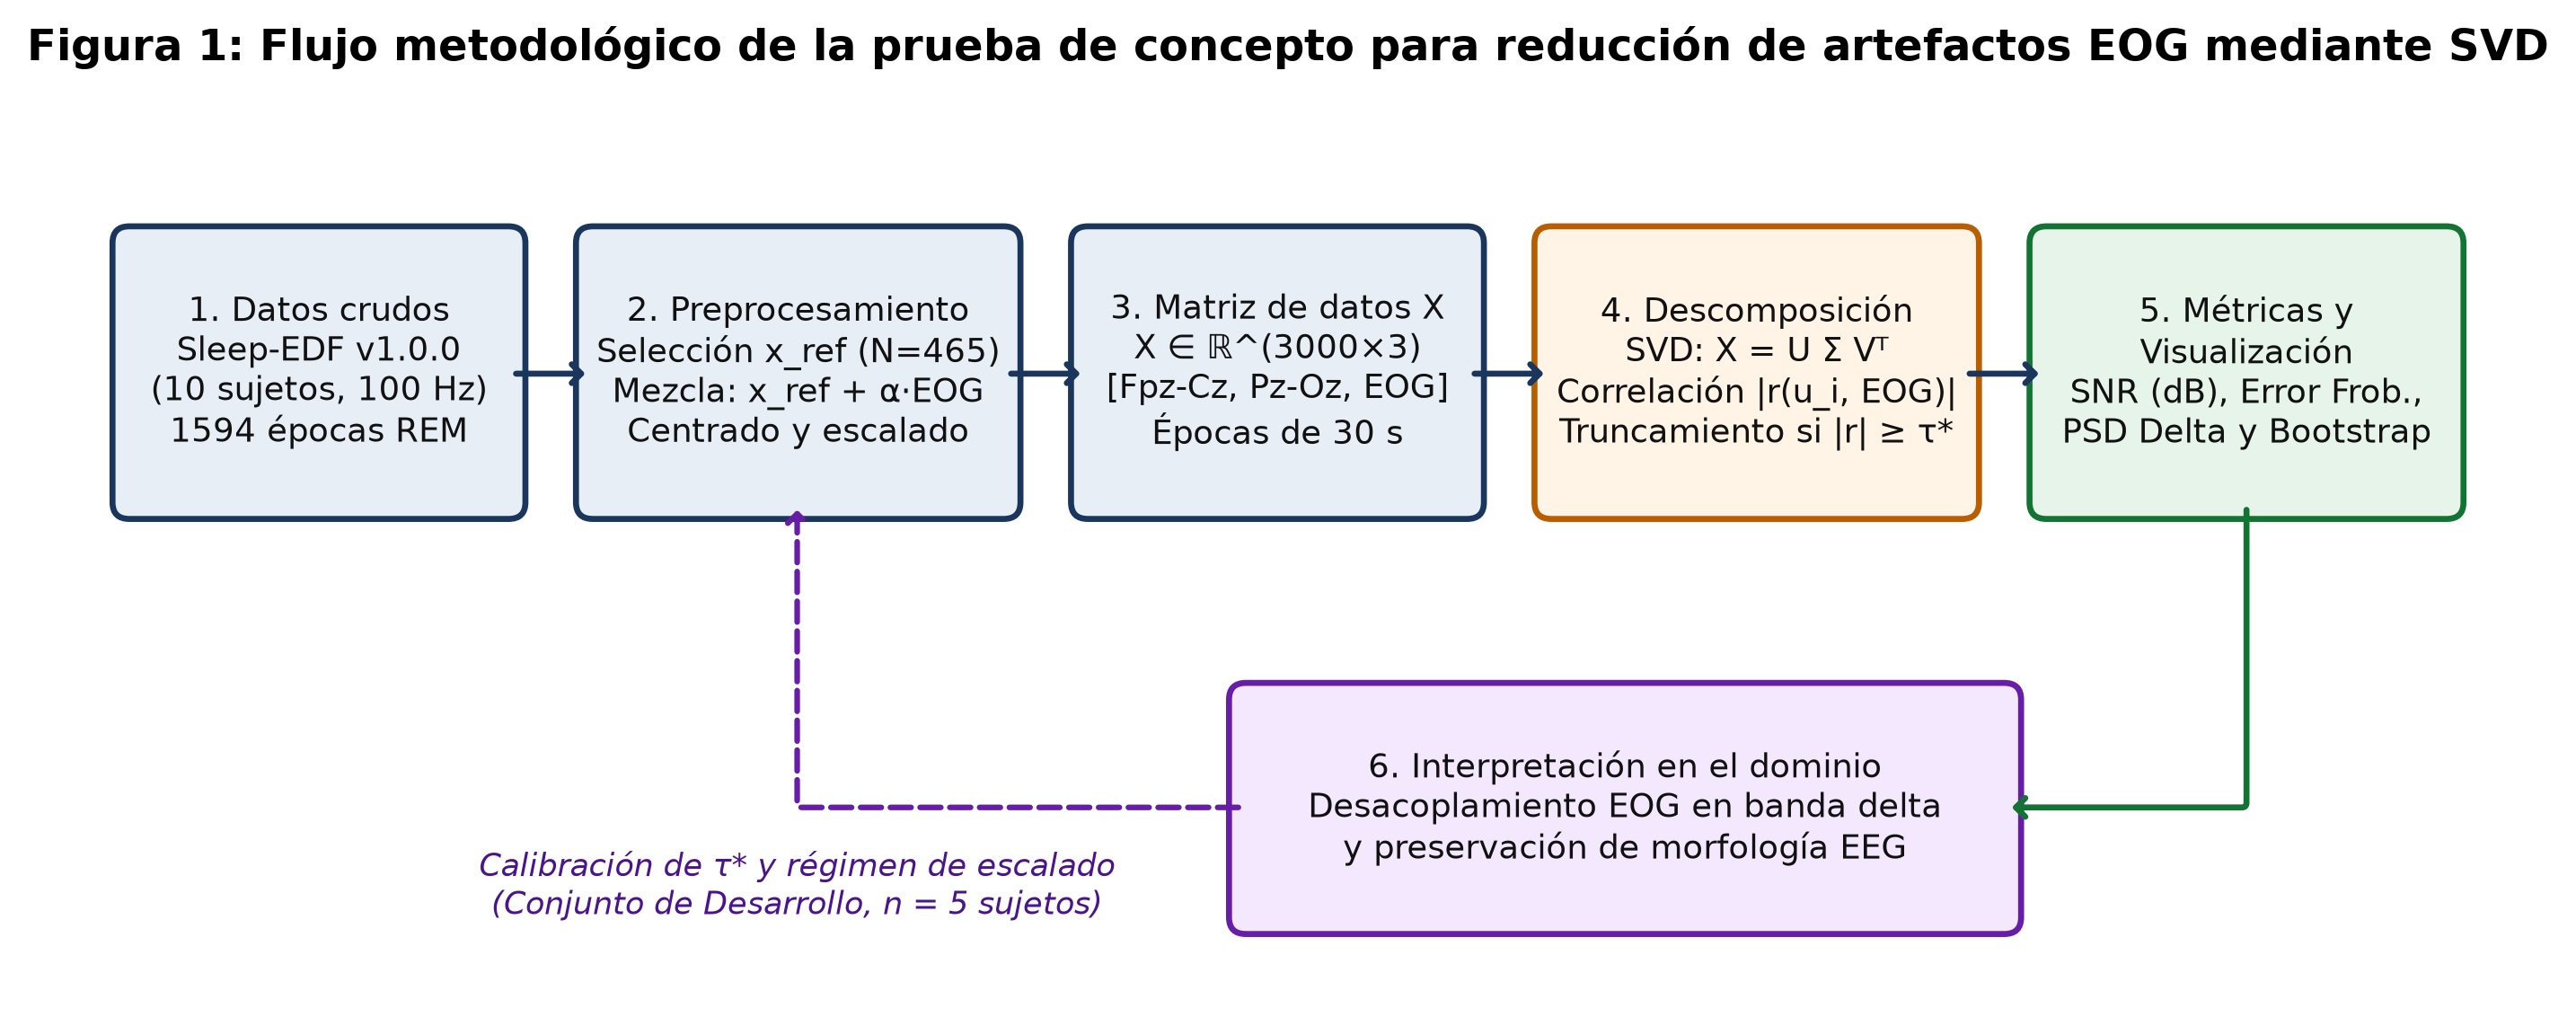

In [1]:
import os
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt, welch

DATA_DIR = r"C:\Users\nicol\.gemini\antigravity\scratch\ponencia_svd_rem\data"
FIG_DIR  = r"C:\Users\nicol\.gemini\antigravity\scratch\ponencia_svd_rem\figures"

# Carga de los 10 sujetos reales descargados de Sleep-EDF Expanded v1.0.0 (PhysioNet)
npz = np.load(os.path.join(DATA_DIR, "sleep_edf_rem_10subjects.npz"))
X_all = npz["X_rem"].astype(np.float64)  # Dimensiones: (1594 épocas REM, 3000 muestras, 3 canales)
df_meta = pd.read_csv(os.path.join(DATA_DIR, "rem_epochs_metadata.csv"))
df_subj = pd.read_csv(os.path.join(DATA_DIR, "subjects_table_complete.csv"))

print(f"Dimensiones del tensor global de épocas REM: {X_all.shape} -> (épocas, muestras a 100 Hz, canales [Fpz-Cz, Pz-Oz, EOG])")
print(f"Total de épocas REM de 30 s extraídas: {len(df_meta)} ({len(df_meta)*0.5:.1f} minutos = {len(df_meta)*0.5/60:.2f} horas de sueño REM)")
print("\nResumen por sujeto y partición experimental (Desarrollo vs. Evaluación):")
print(df_subj[["subject_id", "psg_file", "split", "total_records_30s", "rem_bouts", "rem_epochs_30s", "rem_duration_min", "n_ref_epochs"]].to_string(index=False))

## 2. Selección de épocas de referencia ($x_{\text{ref}}$) y banco de mezclas sintéticas (Objetivo 2)

Para evaluar objetivamente la fidelidad de reconstrucción sin depender de una señal cerebral subyacente desconocida, se seleccionan épocas REM de referencia ($x_{\text{ref}}$) que satisfacen tres criterios simultáneos:
1. **Desacoplamiento basal EEG-EOG:** $|r(\text{Fpz-Cz}, \text{EOG})| < 0.15$ y $|r(\text{Pz-Oz}, \text{EOG})| < 0.15$.
2. **Ausencia de saturación o artefacto muscular/movimiento en EEG:** $\sigma_{\text{EEG}} < 25\,\mu\text{V}$ y $\max_t |x_{\text{EEG}}(t)| < 120\,\mu\text{V}$.
3. **Presencia de actividad ocular genuina en el canal EOG:** $\sigma_{\text{EOG}} > 15\,\mu\text{V}$.

Siguiendo la distribución topográfica anteroposterior reportada por Waterman et al. (1992), se inyecta contaminación controlada sobre los canales EEG centrados:
$$x_{\text{cont, Fpz-Cz}}(t) = x_{\text{ref, Fpz-Cz}}(t) + \alpha \cdot eog(t), \qquad x_{\text{cont, Pz-Oz}}(t) = x_{\text{ref, Pz-Oz}}(t) + (0.30\,\alpha) \cdot eog(t)$$
con niveles de contaminación $\alpha \in \{0.25, 0.50, 0.80\}$.

Épocas de referencia seleccionadas: N = 465 (Desarrollo: 282, Evaluación: 183)

Estadísticos descriptivos de las épocas de referencia (unidades en uV):
       std_fpz  std_pzoz  std_eog  ptp_eog  corr_fpz_eog  corr_pzoz_eog
count  465.000   465.000  465.000  465.000       465.000        465.000
mean     9.678     7.814   33.227  280.426        -0.018         -0.022
std      2.838     2.962   17.703  148.712         0.081          0.076
min      4.828     3.000   15.053   82.674        -0.149         -0.150
25%      7.651     5.842   20.287  163.516        -0.082         -0.082
50%      9.148     6.977   27.124  243.583        -0.023         -0.030
75%     11.106     9.574   40.358  351.116         0.043          0.034
max     21.509    23.116  120.290  815.568         0.150          0.147

Curva de calibración del umbral τ en Desarrollo (α = 0.50):
           mean_snr_fpz_db             mean_components_removed            
scale_mode      dev_zscore physical_uV              dev_zscore p

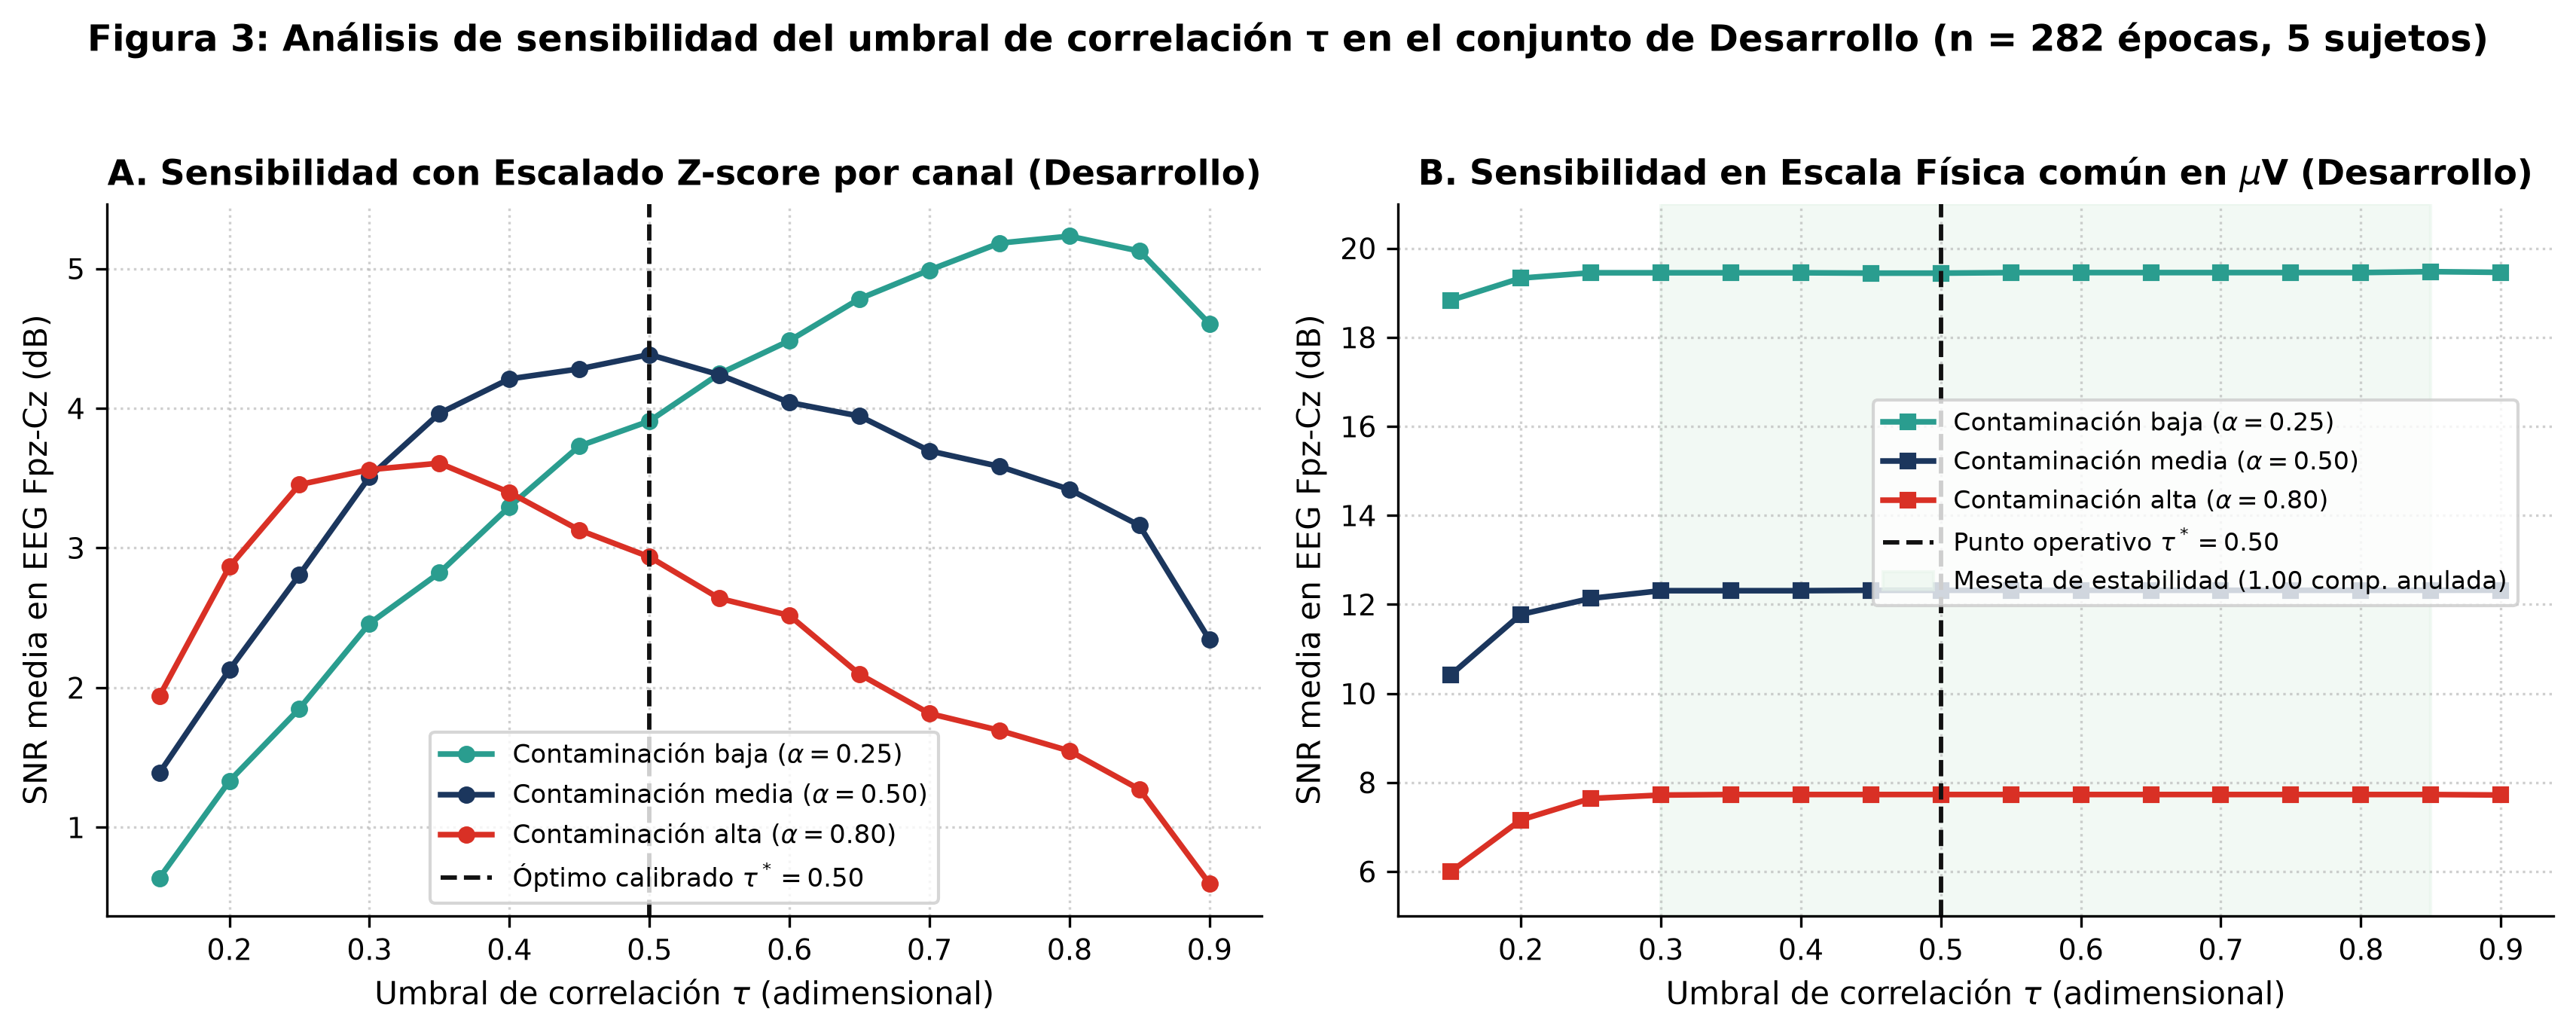

In [2]:
# Filtrado de épocas REM de referencia (x_ref)
max_abs_fpz  = np.max(np.abs(X_all[:, :, 0] - np.mean(X_all[:, :, 0], axis=1, keepdims=True)), axis=1)
max_abs_pzoz = np.max(np.abs(X_all[:, :, 1] - np.mean(X_all[:, :, 1], axis=1, keepdims=True)), axis=1)

mask_ref = (
    (df_meta["corr_fpz_eog"].abs() < 0.15) &
    (df_meta["corr_pzoz_eog"].abs() < 0.15) &
    (df_meta["std_fpz"] < 25.0) &
    (df_meta["std_pzoz"] < 25.0) &
    (max_abs_fpz < 120.0) &
    (max_abs_pzoz < 120.0) &
    (df_meta["std_eog"] > 15.0)
)

X_ref = X_all[mask_ref] - np.mean(X_all[mask_ref], axis=1, keepdims=True)
df_ref = df_meta[mask_ref].copy().reset_index(drop=True)

dev_mask  = (df_ref["split"] == "Desarrollo").values
eval_mask = (df_ref["split"] == "Evaluacion").values

print(f"Épocas de referencia seleccionadas: N = {len(df_ref)} (Desarrollo: {dev_mask.sum()}, Evaluación: {eval_mask.sum()})")
print("\nEstadísticos descriptivos de las épocas de referencia (unidades en uV):")
print(df_ref[["std_fpz", "std_pzoz", "std_eog", "ptp_eog", "corr_fpz_eog", "corr_pzoz_eog"]].describe().round(3).to_string())

# Tabla de calibración del umbral tau en el conjunto de Desarrollo (alpha = 0.50)
df_sens = pd.read_csv(os.path.join(DATA_DIR, "threshold_sensitivity_dev.csv"))
print("\nCurva de calibración del umbral τ en Desarrollo (α = 0.50):")
piv_sens = df_sens[df_sens["alpha"] == 0.50].pivot(index="tau", columns="scale_mode", values=["mean_snr_fpz_db", "mean_components_removed"])
print(piv_sens.round(3).to_string())

## 3. Espectro de Valores Singulares y Resultados Cuantitativos en Evaluación (Objetivos 3, 5 y 6)

Para cada época de $30\text{ s}$ ($N = 3000$ muestras a $100\text{ Hz}$), la matriz multicanal $X \in \mathbb{R}^{3000 \times 3}$ se descompone mediante SVD de rango económico:
$$X = U \Sigma V^\top = \sum_{i=1}^{3} \sigma_i u_i v_i^\top, \qquad \sigma_1 \ge \sigma_2 \ge \sigma_3 \ge 0$$
Se evalúan las métricas del Cuadro 1 de la guía (valores singulares $\sigma_i$, porcentaje de energía capturada $E_i = \sigma_i^2 / \sum_j \sigma_j^2$, error relativo de reconstrucción en norma de Frobenius $\|X_{\text{EEG,ref}} - \hat{X}_{\text{EEG}}\|_F / \|X_{\text{EEG,ref}}\|_F$) junto con las métricas de la pregunta de investigación ($\text{SNR}$ en dB, correlación de Pearson $r$, $\text{RMSE}$ en $\mu\text{V}$ y error relativo de potencia en banda delta $0.5\text{--}4\text{ Hz}$).

=== TABLA 1: ESPECTRO DE VALORES SINGULARES Y ENERGÍA CAPTURADA (Evaluación, n = 183 épocas) ===
                     sigma_1          sigma_2         sigma_3         energy_1_pct        energy_2_pct        energy_3_pct       corr_u1_eog       corr_u2_eog       corr_u3_eog       n_removed      
                        mean      std    mean     std    mean     std         mean    std         mean    std         mean   std        mean   std        mean   std        mean   std      mean   std
mode          alpha                                                                                                                                                                                   
SVD_Fisico_uV 0.25   1888.07   997.22  631.74  165.64  333.93  104.25        82.25  11.66        13.78   9.25         3.97  3.19        0.98  0.07        0.12  0.13        0.04  0.03      1.01  0.07
              0.50   2071.70  1082.75  595.51  155.56  321.09   98.24        86.03   9.53        10.77   7.

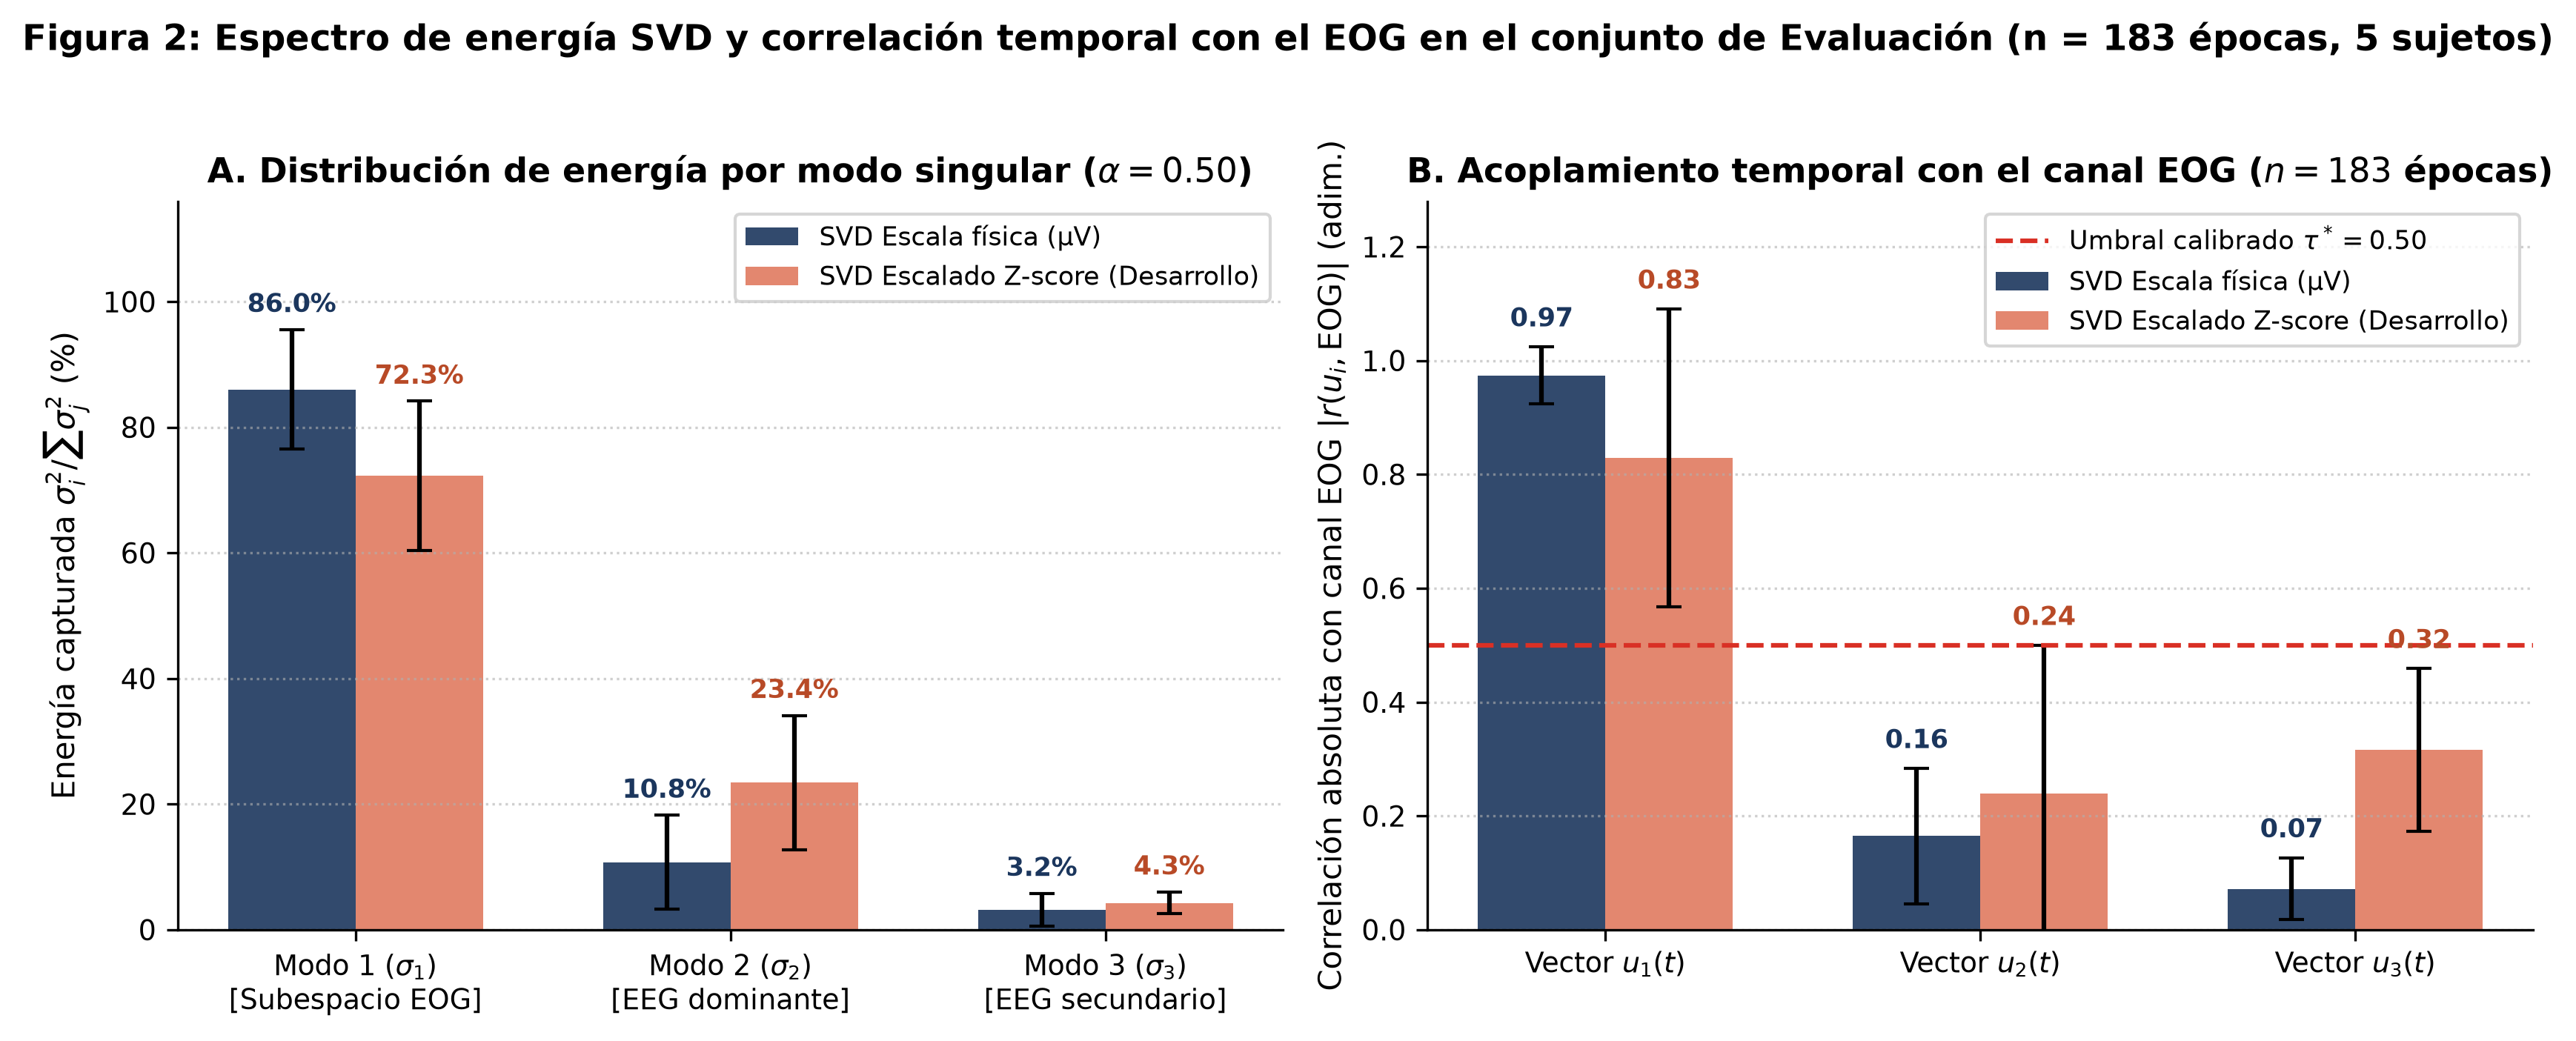

In [3]:
df_spec = pd.read_csv(os.path.join(DATA_DIR, "eval_svd_spectrum.csv"))
df_eval = pd.read_csv(os.path.join(DATA_DIR, "eval_metrics_all_epochs.csv"))
df_boot = pd.read_csv(os.path.join(DATA_DIR, "bootstrap_ci95_results.csv"))

print("=== TABLA 1: ESPECTRO DE VALORES SINGULARES Y ENERGÍA CAPTURADA (Evaluación, n = 183 épocas) ===")
spec_tbl = df_spec.groupby(["mode", "alpha"])[
    ["sigma_1", "sigma_2", "sigma_3", "energy_1_pct", "energy_2_pct", "energy_3_pct", "corr_u1_eog", "corr_u2_eog", "corr_u3_eog", "n_removed"]
].agg(["mean", "std"]).round(2)
print(spec_tbl.to_string())

print("\n=== TABLA 2: MÉTRICAS DE RECONSTRUCCIÓN EN EVALUACIÓN (n = 183 épocas, 5 sujetos) ===")
eval_tbl = df_eval.groupby(["alpha", "method"])[
    ["snr_fpz_db", "snr_pzoz_db", "rmse_fpz_uv", "corr_fpz", "frob_rel_err_eeg", "delta_psd_rel_err_fpz"]
].agg(["mean", "std"]).round(3)
print(eval_tbl.to_string())

=== TABLA 3: CONTRASTE DE HIPÓTESIS MEDIANTE BOOTSTRAP PAREADO POR SUJETO (B = 10 000 réplicas, IC 95%) ===
 alpha                            comparison  mean_diff_fpz_db  std_diff_fpz_db  subj_ci95_low_fpz  subj_ci95_high_fpz  epoch_ci95_low_fpz  epoch_ci95_high_fpz  pct_epochs_improved_fpz
  0.25            SVD_Zscore vs Sin_procesar             1.128            5.377             -1.355               2.521               0.361                1.907                   43.169
  0.25    SVD_Zscore vs Butterworth_0.5_30Hz             0.729            4.186             -1.238               1.828               0.131                1.321                   54.098
  0.25         SVD_Fisico_uV vs Sin_procesar            14.902            8.180             12.092              16.057              13.718               16.068                   94.536
  0.25 SVD_Fisico_uV vs Butterworth_0.5_30Hz            14.503            6.382             11.958              15.601              13.576              

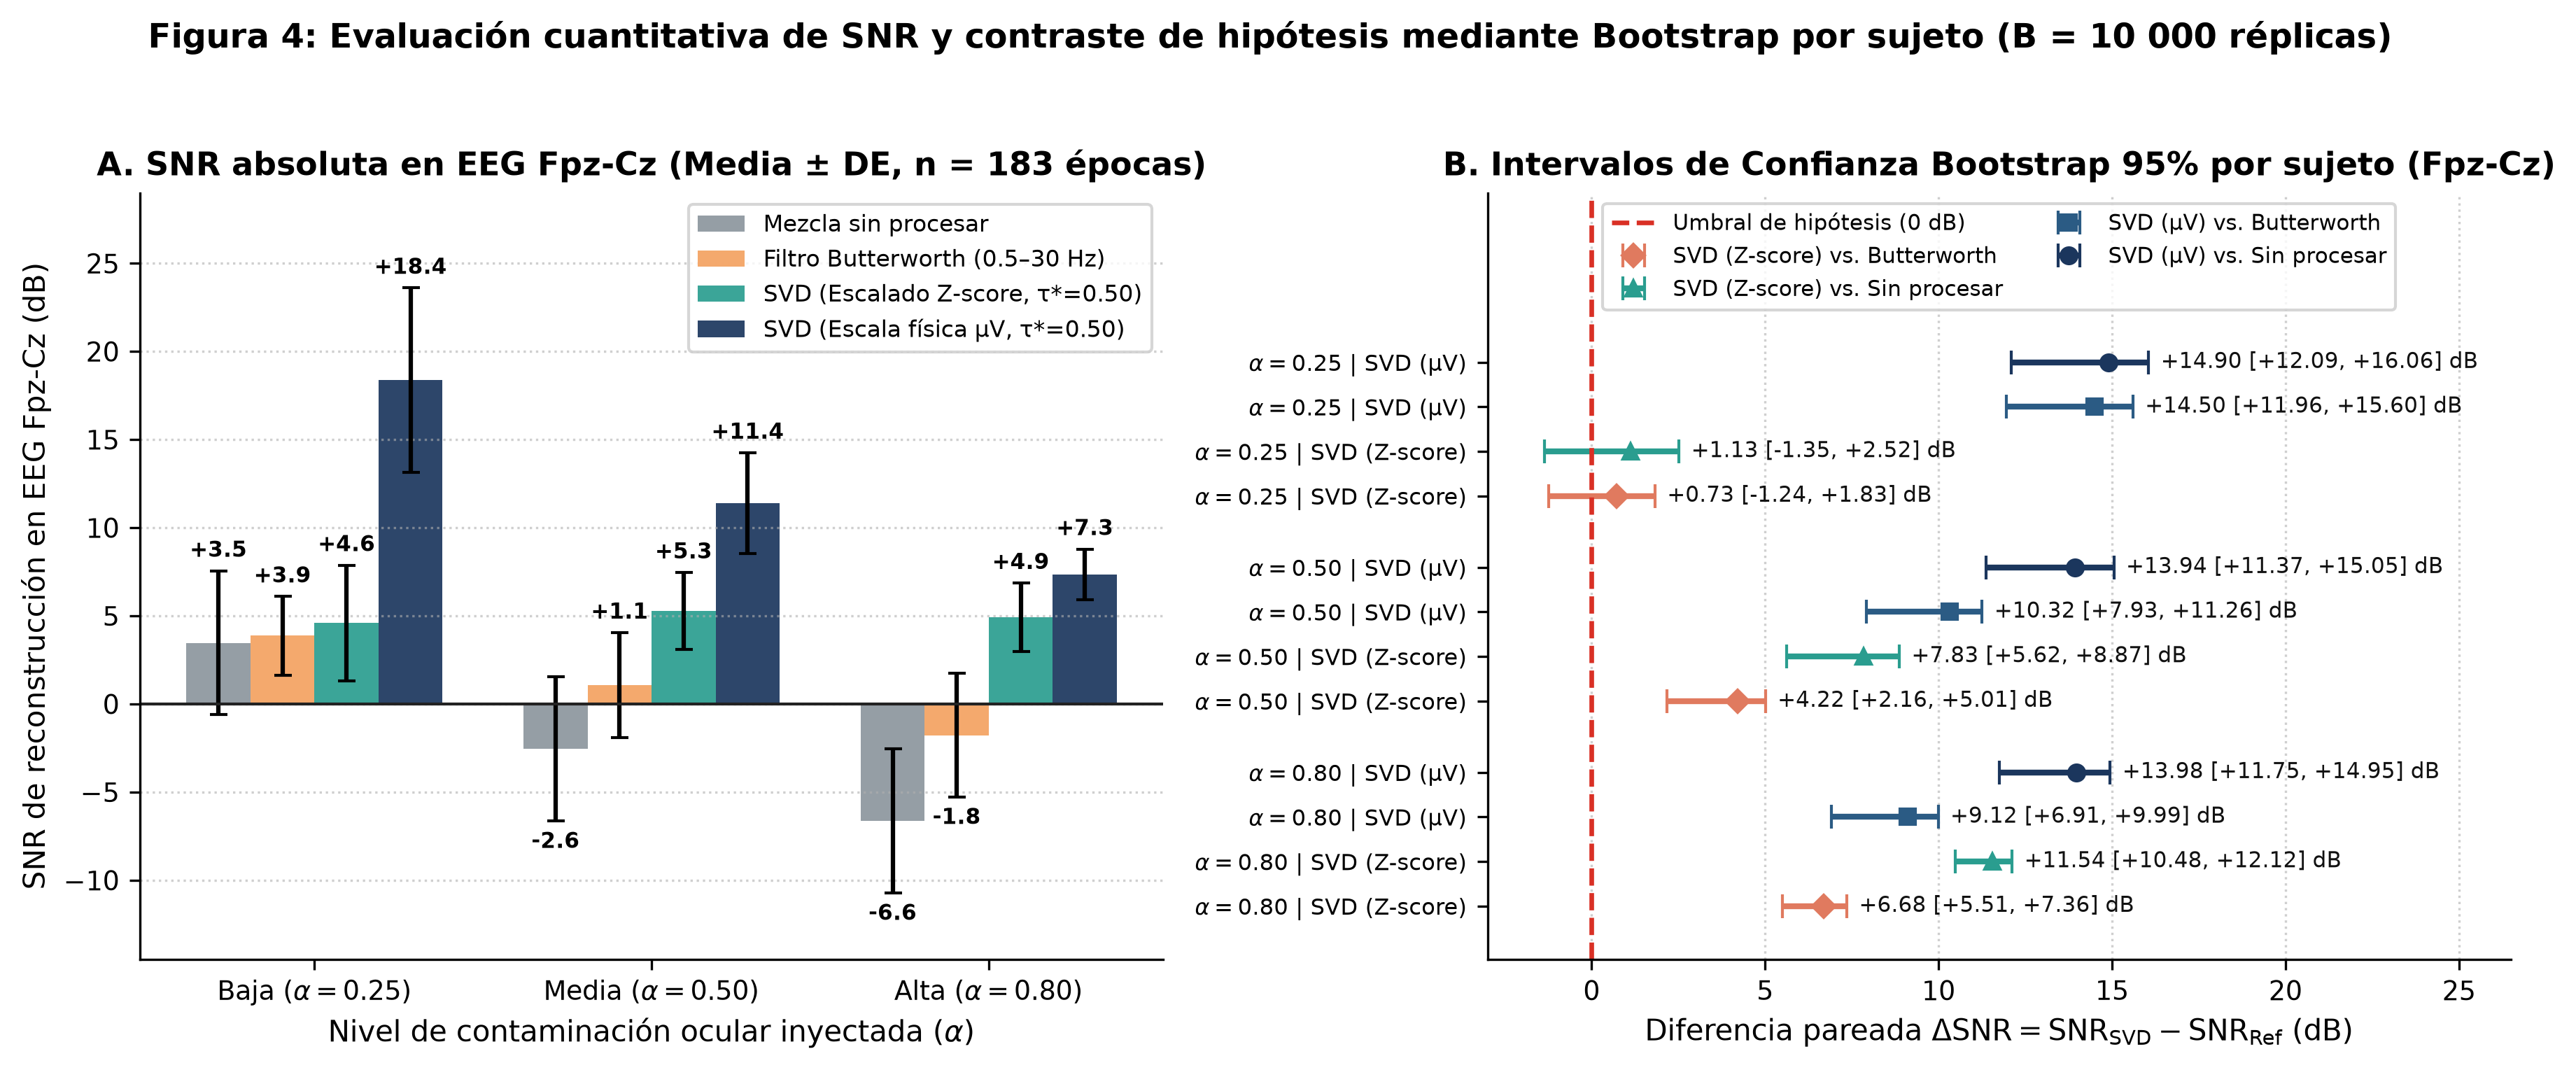

In [4]:
print("=== TABLA 3: CONTRASTE DE HIPÓTESIS MEDIANTE BOOTSTRAP PAREADO POR SUJETO (B = 10 000 réplicas, IC 95%) ===")
cols_boot = [
    "alpha", "comparison", "mean_diff_fpz_db", "std_diff_fpz_db",
    "subj_ci95_low_fpz", "subj_ci95_high_fpz", "epoch_ci95_low_fpz", "epoch_ci95_high_fpz",
    "pct_epochs_improved_fpz"
]
print(df_boot[cols_boot].round(3).to_string(index=False))

## 4. Resultados Cualitativos: Interpretación Física de Componentes, Reconstrucción Espectral y Análisis de Fallos

A continuación se visualizan:
1. **Interpretación física de los vectores singulares temporales ($\sigma_i u_i(t)$) y proyección en el subespacio reducido ($\sigma_1 u_1$ vs. $\sigma_2 u_2$).**
2. **Comparación temporal y en Densidad Espectral de Potencia (PSD Welch en banda delta $0.5\text{--}4\text{ Hz}$) frente a la referencia limpia y al filtro Butterworth.**
3. **Análisis comparativo entre un caso de desacoplamiento exitoso y un caso de fallo por rotación de subespacios bajo escalado Z-score en baja contaminación ($\alpha = 0.25$).**

Pesos espaciales absolutos |V_{1,j}| del primer modo singular (α = 0.50):
              v1_fpz        v1_pzoz        v1_eog       
                mean    std    mean    std   mean    std
mode                                                    
SVD_Fisico_uV  0.502  0.074   0.116  0.029  0.851  0.062
SVD_Zscore     0.615  0.167   0.474  0.213  0.537  0.189


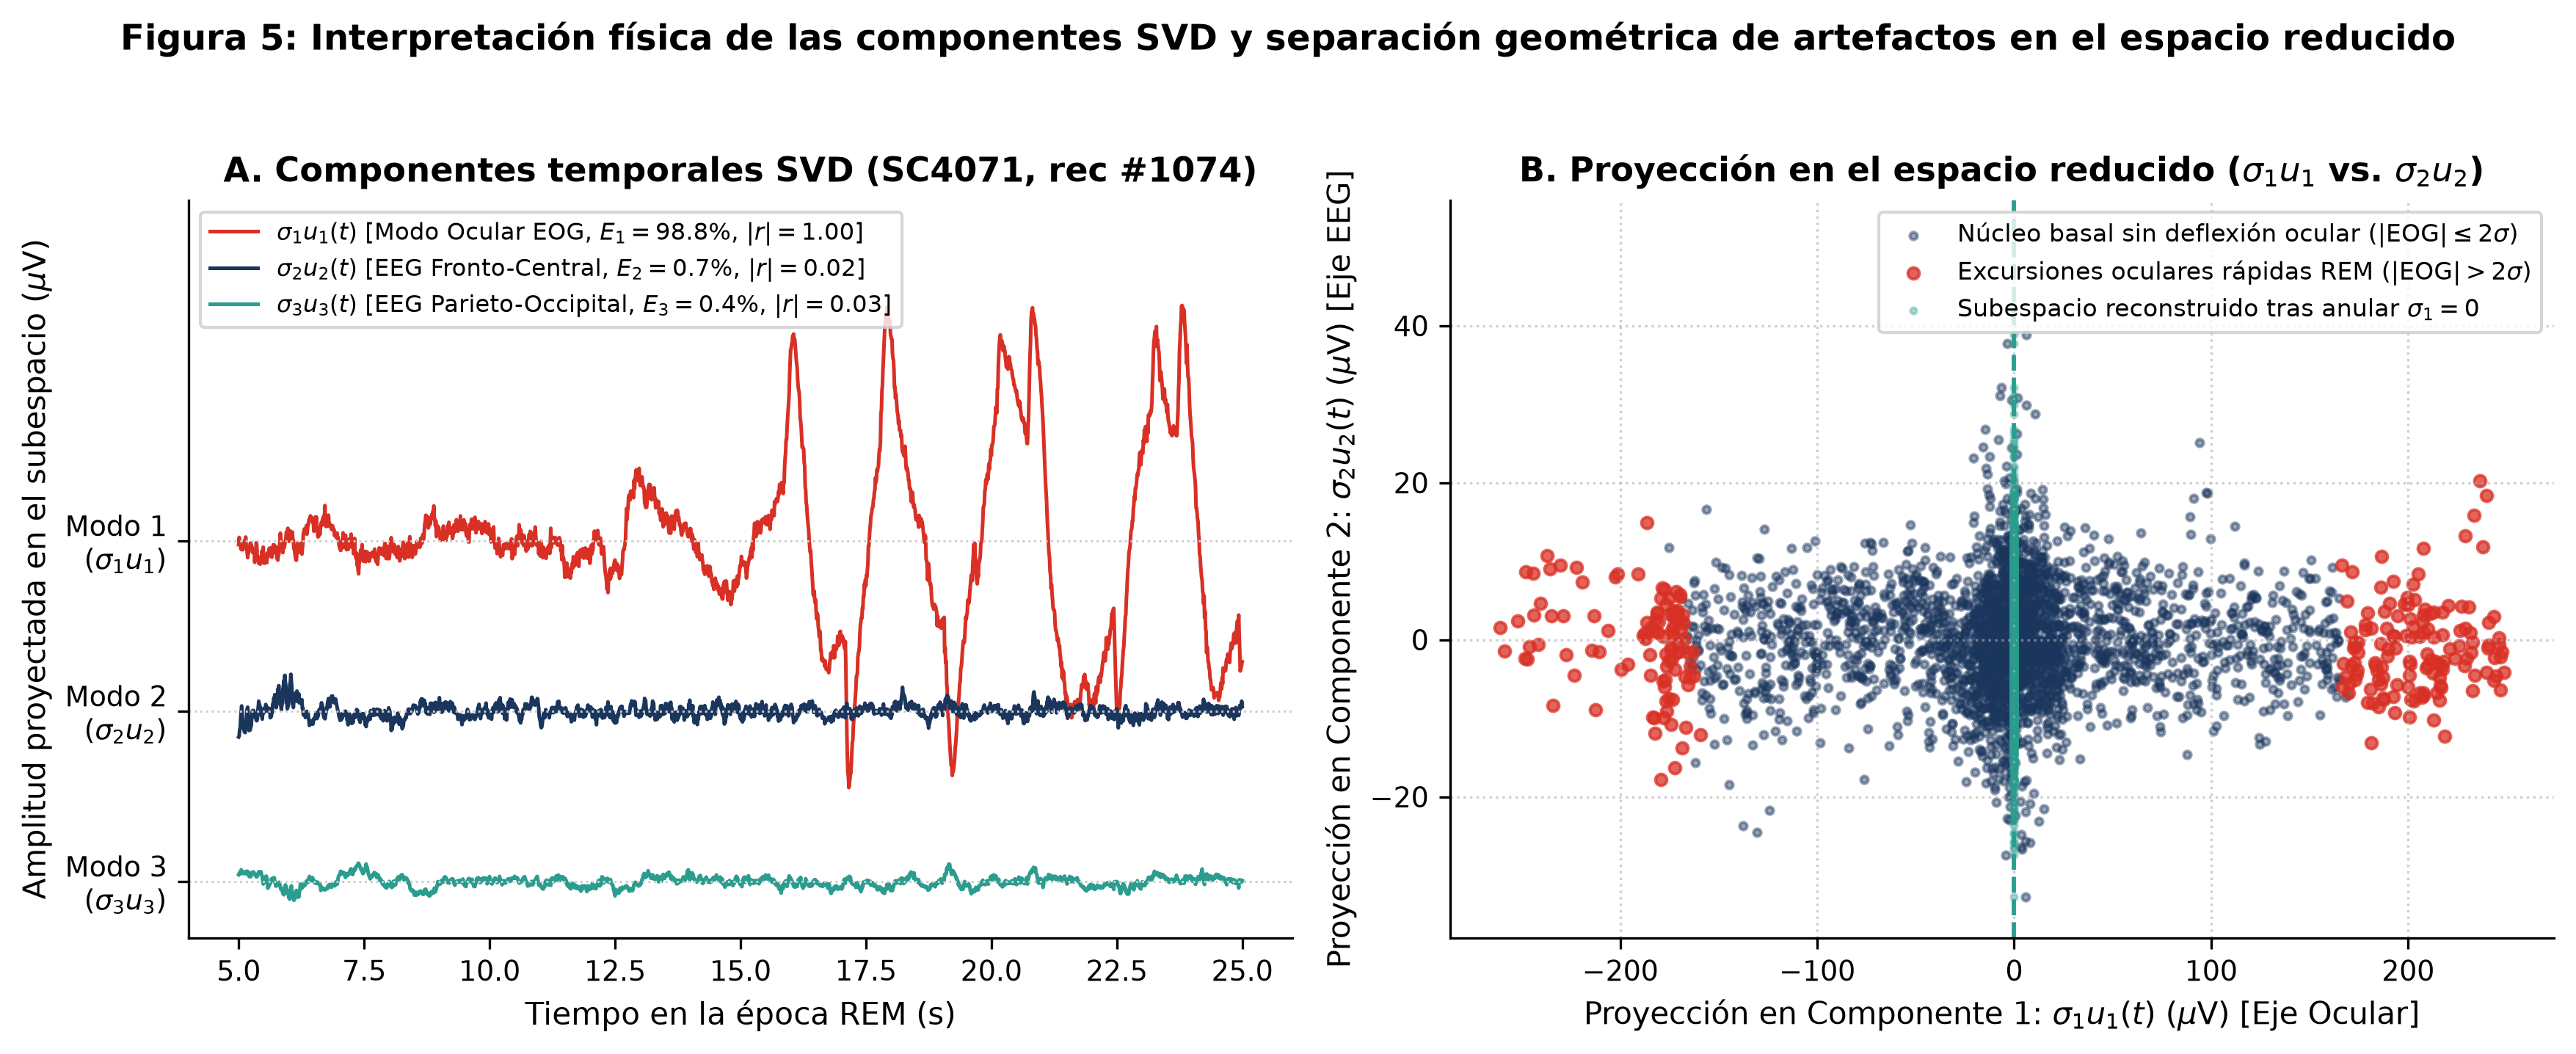

In [5]:
# Resumen de pesos espaciales V^T del primer modo singular (Modo Ocular)
sub_v = df_spec[df_spec["alpha"] == 0.50].groupby("mode")[["v1_fpz", "v1_pzoz", "v1_eog"]].agg(["mean", "std"]).round(3)
print("Pesos espaciales absolutos |V_{1,j}| del primer modo singular (α = 0.50):")
print(sub_v.to_string())

Comparación de error relativo de potencia en banda delta (0.5–4 Hz) y error de Frobenius (α = 0.50):
                     snr_fpz_db        delta_psd_rel_err_fpz        frob_rel_err_eeg       
                           mean    std                  mean    std             mean    std
method                                                                                     
Butterworth_0.5_30Hz      1.065  2.984                 1.263  1.651            0.867  0.305
SVD_Fisico_uV            11.390  2.867                 0.419  0.113            0.257  0.119
SVD_Zscore                5.284  2.176                 0.521  0.238            0.507  0.151
Sin_procesar             -2.550  4.086                 1.760  2.199            1.305  0.636


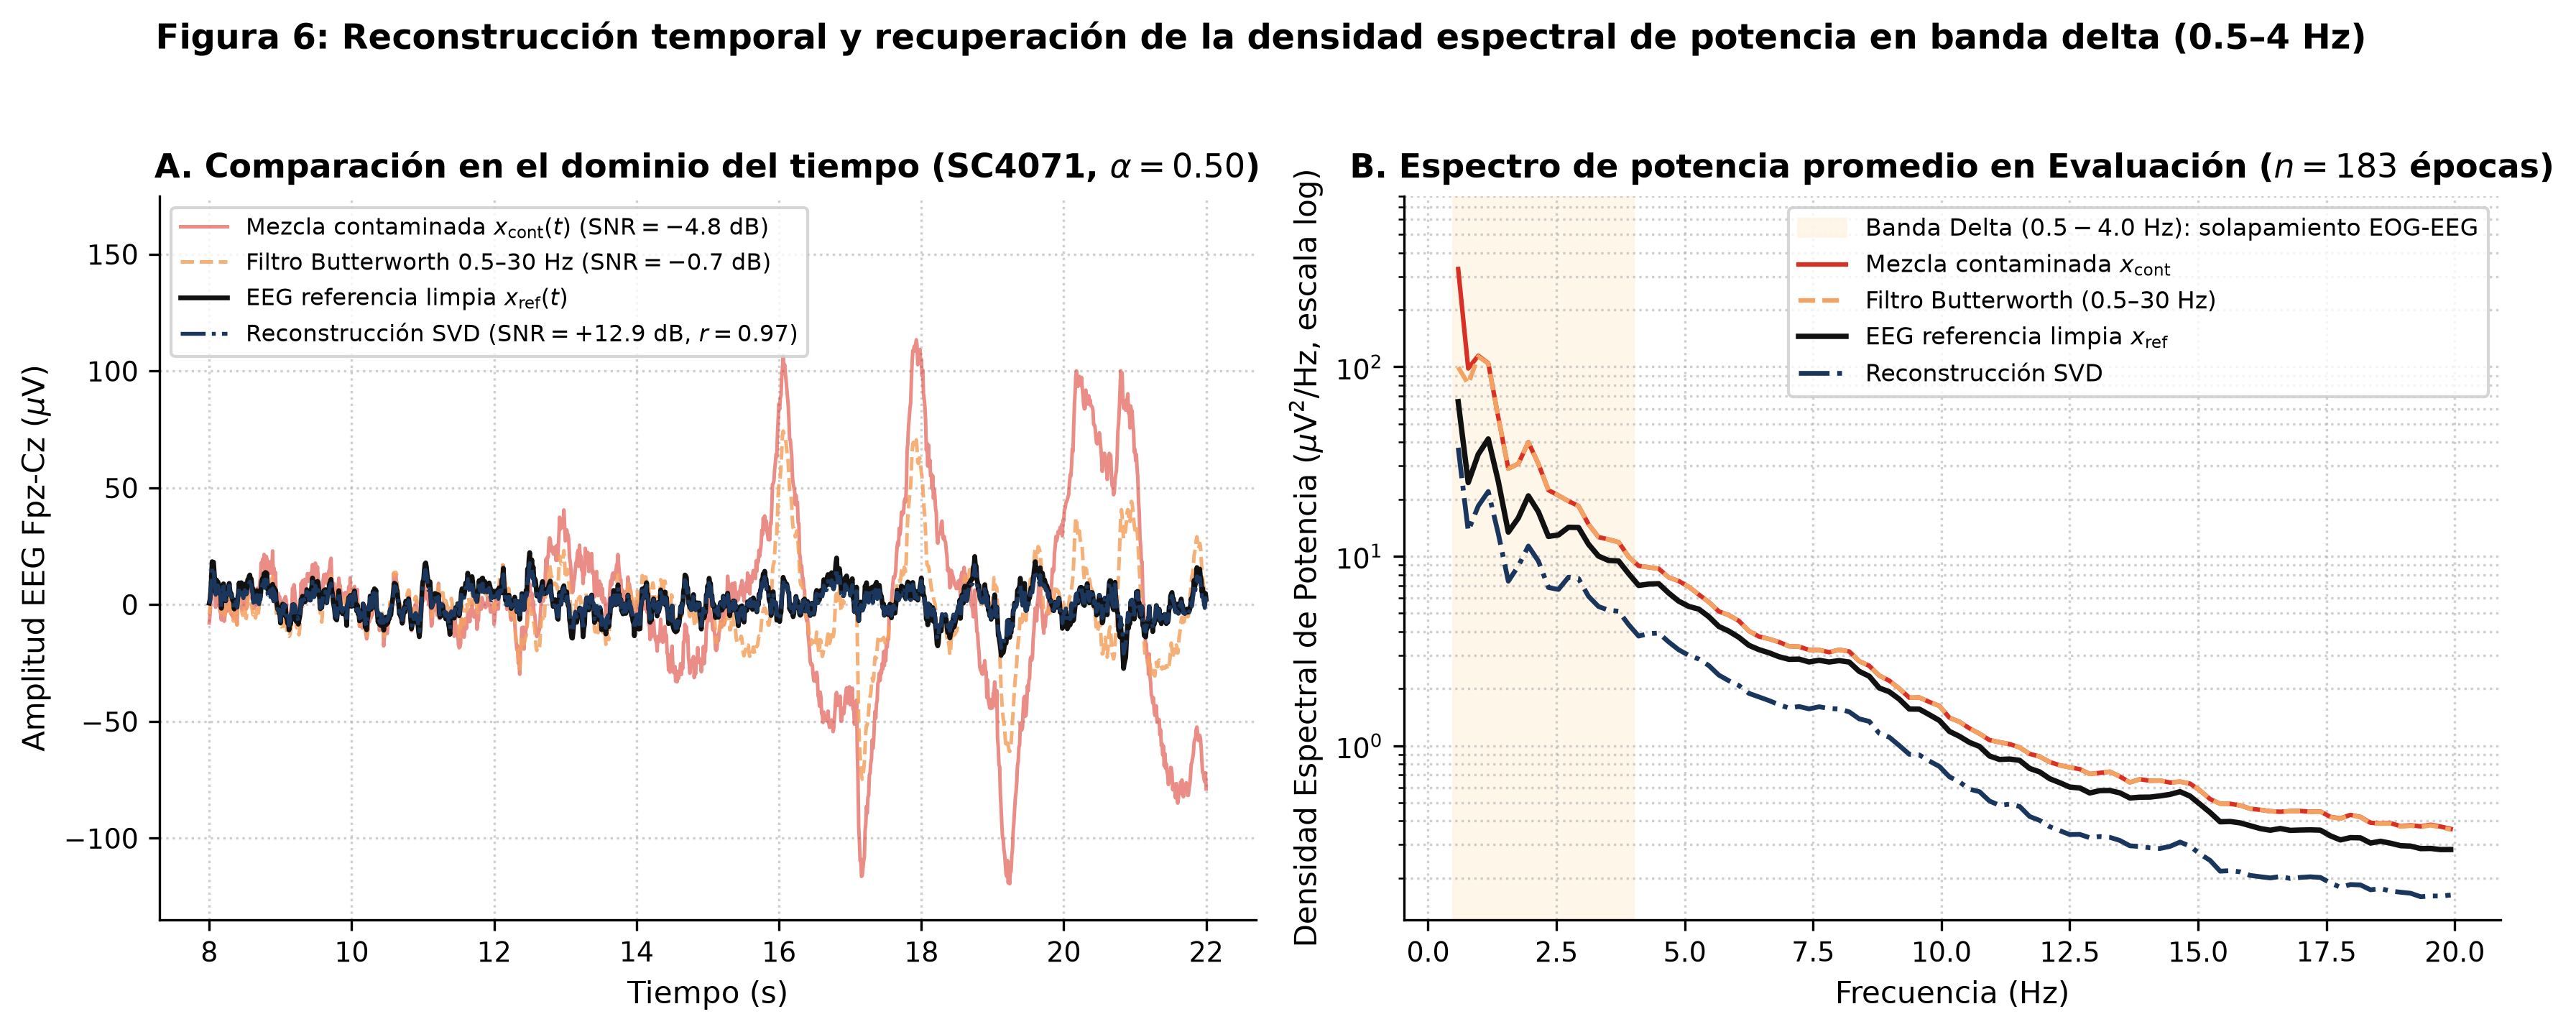

In [6]:
# Verificación de recuperación espectral en banda delta (0.5 - 4.0 Hz) para α = 0.50
sub_delta = df_eval[df_eval["alpha"] == 0.50].groupby("method")[["snr_fpz_db", "delta_psd_rel_err_fpz", "frob_rel_err_eeg"]].agg(["mean", "std"]).round(3)
print("Comparación de error relativo de potencia en banda delta (0.5–4 Hz) y error de Frobenius (α = 0.50):")
print(sub_delta.to_string())

Diagnóstico de acoplamiento subespacial en α = 0.25 (Evaluación):
  SVD_Zscore     : 1 comp. anulada =  55.7%, >=2 comp. anuladas (sobre-truncamiento) =  44.3%, 0 comp. =  0.0%
  SVD_Fisico_uV  : 1 comp. anulada =  99.5%, >=2 comp. anuladas (sobre-truncamiento) =   0.5%, 0 comp. =  0.0%


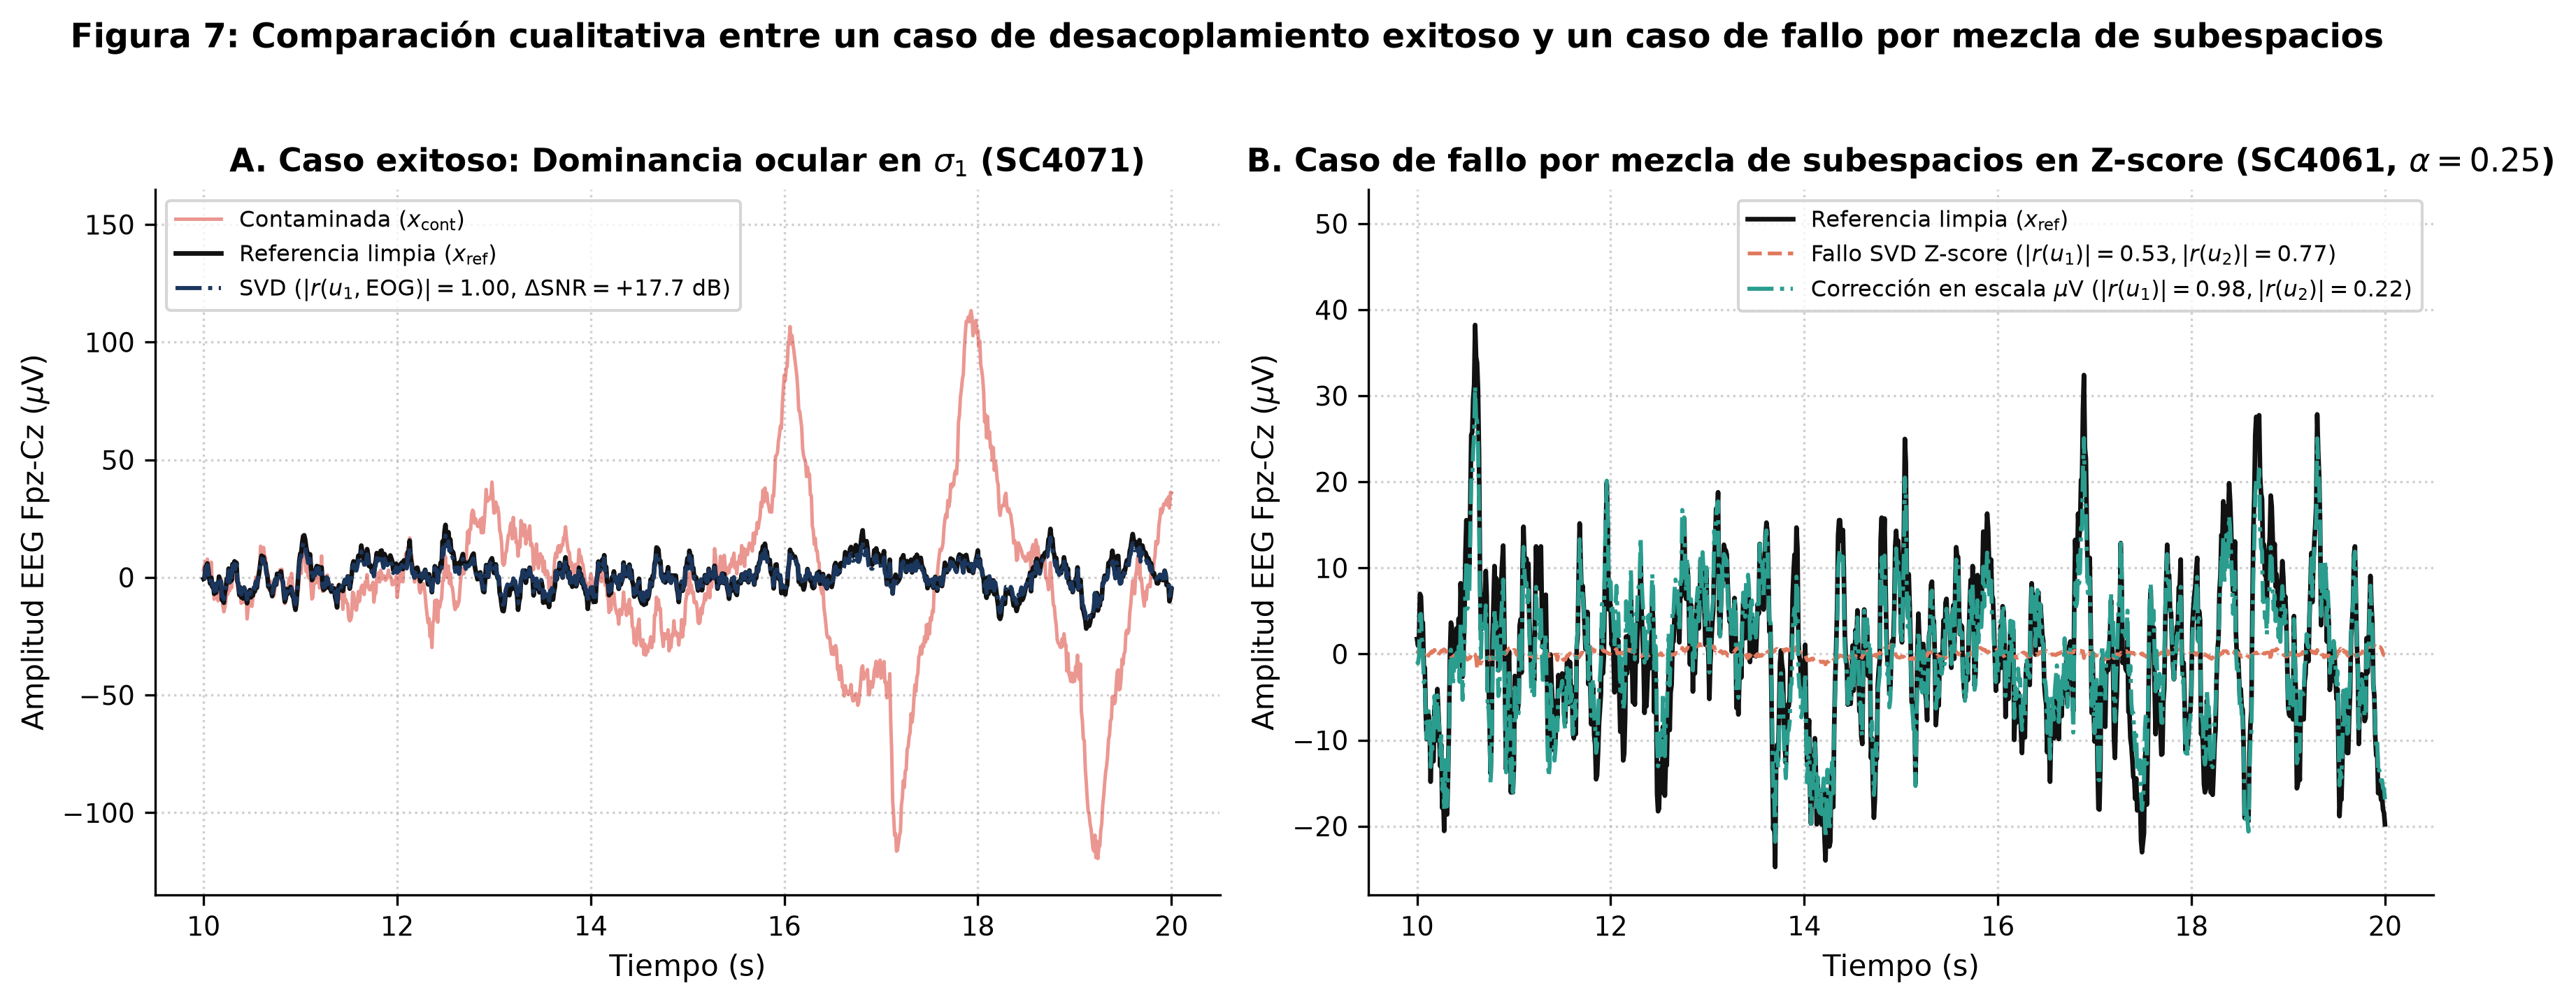

In [7]:
# Diagnóstico cuantitativo del caso de éxito vs. caso de fallo por mezcla de subespacios
print("Diagnóstico de acoplamiento subespacial en α = 0.25 (Evaluación):")
for mode_n in ["SVD_Zscore", "SVD_Fisico_uV"]:
    s_m = df_spec[(df_spec["alpha"] == 0.25) & (df_spec["mode"] == mode_n)]
    frac_multi = (s_m["n_removed"] >= 2).mean() * 100.0
    frac_none  = (s_m["n_removed"] == 0).mean() * 100.0
    frac_exact = (s_m["n_removed"] == 1).mean() * 100.0
    print(f"  {mode_n:15s}: 1 comp. anulada = {frac_exact:5.1f}%, >=2 comp. anuladas (sobre-truncamiento) = {frac_multi:5.1f}%, 0 comp. = {frac_none:4.1f}%")